<a href="https://colab.research.google.com/github/MominaShahzad100/Python-Git-Project/blob/main/AI_LAB_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Plot style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 7043
Number of columns: 21

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetServic

In [4]:
print("Data Types of All Columns:")
print(df.dtypes)

Data Types of All Columns:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [5]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Total missing values: 11


In [6]:
df_clean = df.copy()

# Fill missing TotalCharges with median
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(
    df_clean["TotalCharges"].median()
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nTotal missing values after cleaning:",
      df_clean.isnull().sum().sum())

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values after cleaning: 0


In [7]:
print("Descriptive Statistics for Numerical Variables:")

df_clean.describe()

Descriptive Statistics for Numerical Variables:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928
std,0.368612,24.559481,30.090047,2265.270398
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [8]:
print("Descriptive Statistics for Categorical Variables:")

df_clean.describe(include="object")

Descriptive Statistics for Categorical Variables:


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


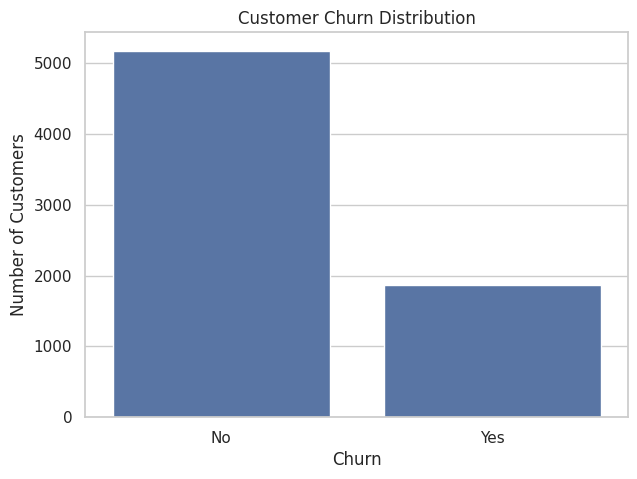

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

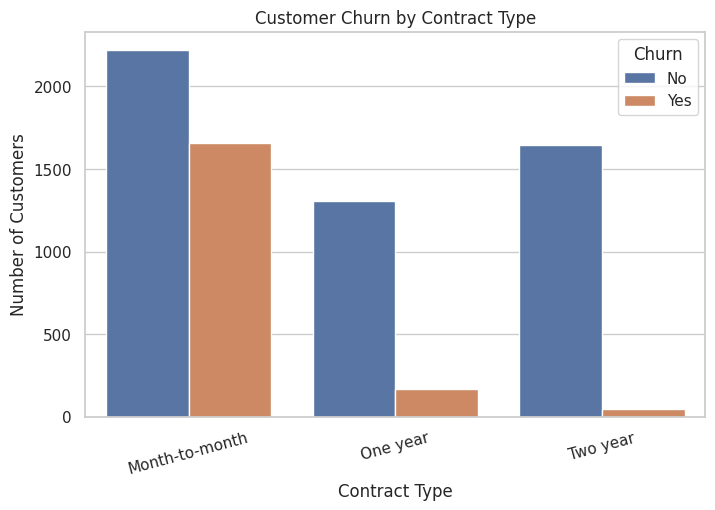

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

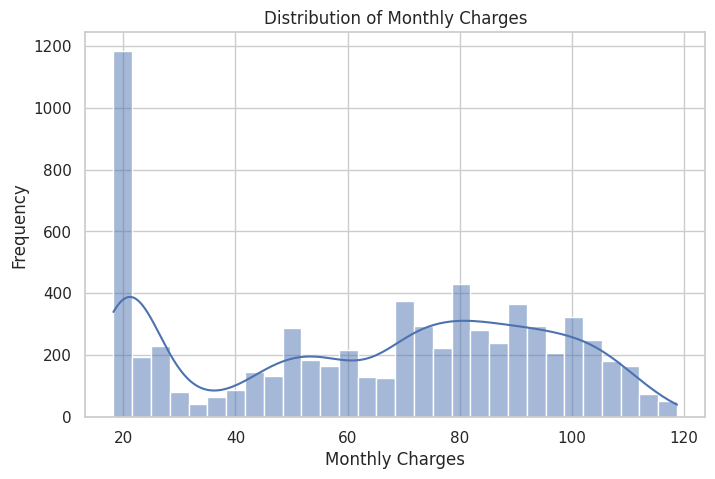

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="MonthlyCharges", bins=30, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")

plt.show()

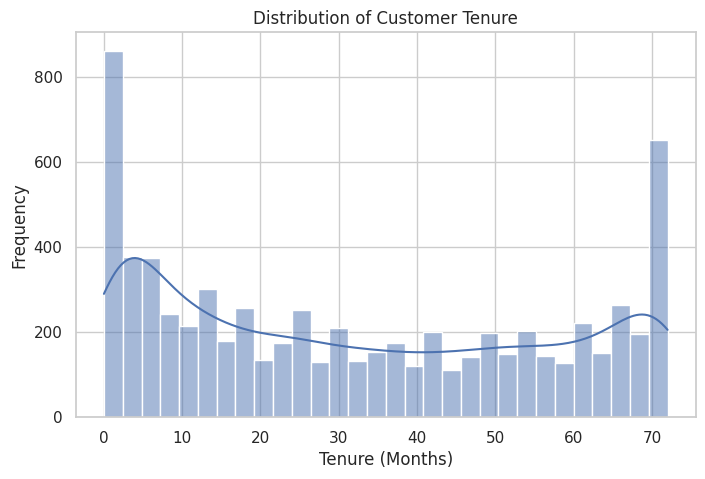

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="tenure", bins=30, kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Frequency")

plt.show()

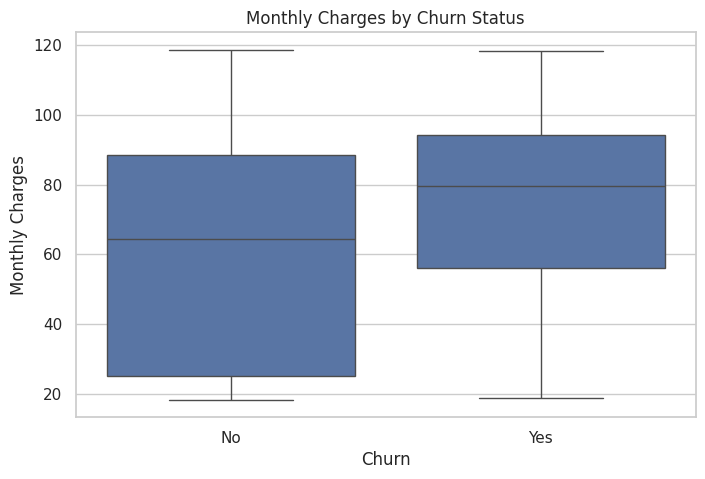

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

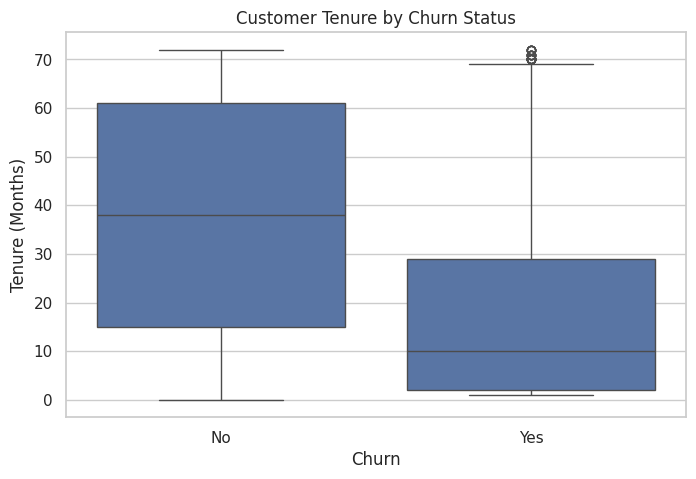

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [15]:
df_corr = df_clean.copy()

df_corr["ChurnNumeric"] = df_corr["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Select numerical columns
numeric_df = df_corr.select_dtypes(include=np.number)

print("Numerical columns:")
print(numeric_df.columns.tolist())

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnNumeric']


In [16]:
correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")

correlation_matrix

Correlation Matrix:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,ChurnNumeric
SeniorCitizen,1.000000,0.016567,0.220173,0.102652,0.150889
tenure,0.016567,1.000000,0.247900,0.825464,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.650864,0.193356
TotalCharges,0.102652,0.825464,0.650864,1.000000,-0.199037
ChurnNumeric,0.150889,-0.352229,0.193356,-0.199037,1.000000


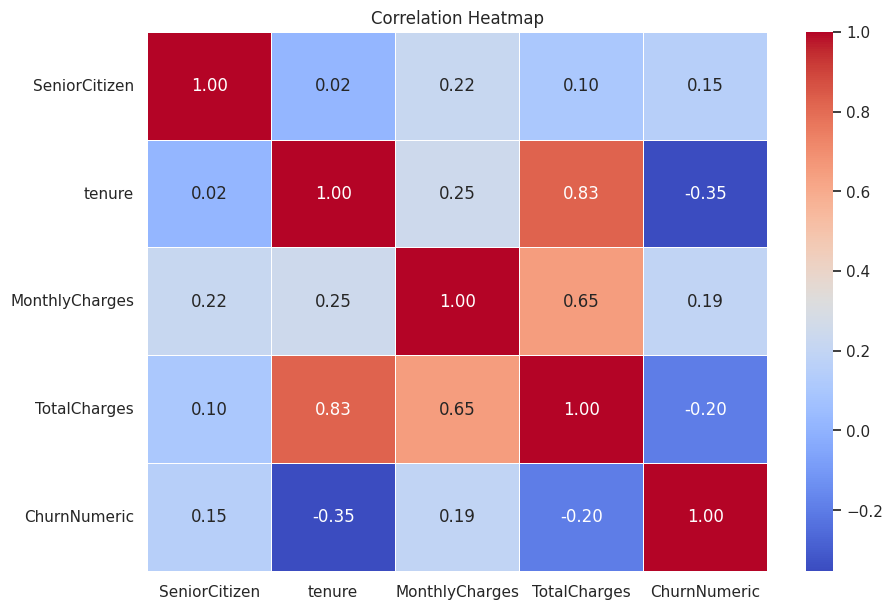

In [17]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

In [18]:
churn_correlation = correlation_matrix["ChurnNumeric"].sort_values(
    ascending=False
)

print("Correlation of Numerical Features with Churn:")
print(churn_correlation)

Correlation of Numerical Features with Churn:
ChurnNumeric      1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.199037
tenure           -0.352229
Name: ChurnNumeric, dtype: float64


In [19]:
categorical_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print("Churn Rate by", column)

    churn_rate = pd.crosstab(
        df_clean[column],
        df_clean["Churn"],
        normalize="index"
    ) * 100

    print(churn_rate.round(2))


Churn Rate by gender
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Churn Rate by SeniorCitizen
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68

Churn Rate by Partner
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Churn Rate by Dependents
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

Churn Rate by PhoneService
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

Churn Rate by MultipleLines
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

Churn Rate by InternetService
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn Rate by 

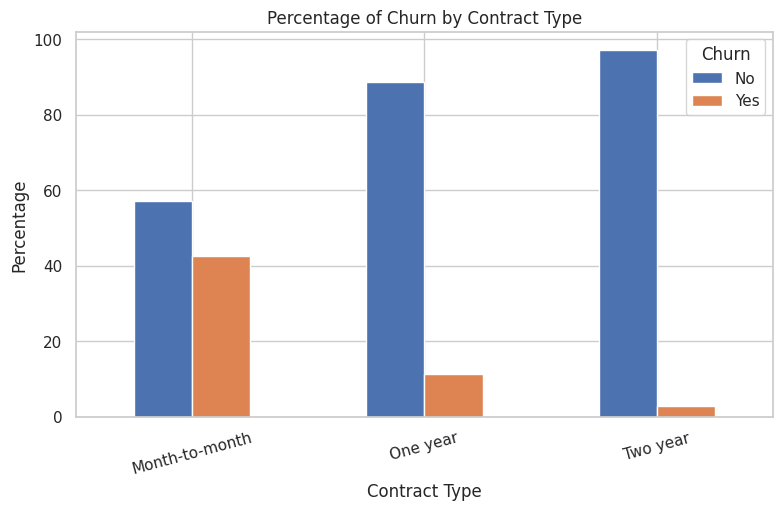

In [20]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Percentage of Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.show()

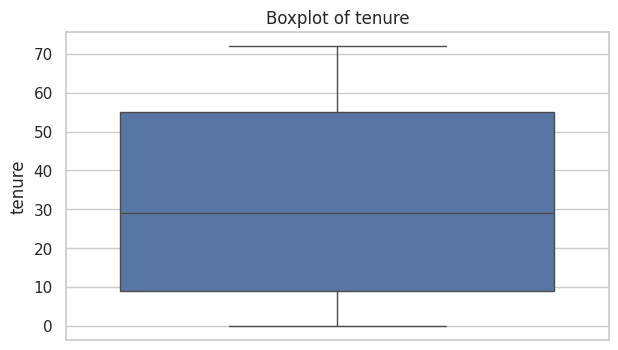

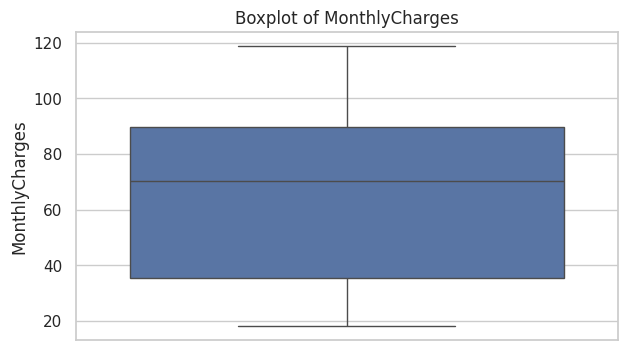

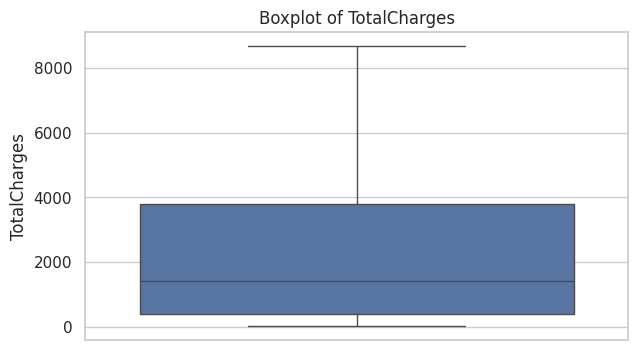

In [21]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df_clean, y=column)

    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)

    plt.show()

In [22]:
def find_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return Q1, Q3, IQR, lower_bound, upper_bound, outliers


for column in numerical_columns:

    Q1, Q3, IQR, lower, upper, outliers = find_outliers_iqr(
        df_clean,
        column
    )

    print("\n", "=" * 60)
    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of possible outliers:", len(outliers))


Column: tenure
Q1: 9.0
Q3: 55.0
IQR: 46.0
Lower Bound: -60.0
Upper Bound: 124.0
Number of possible outliers: 0

Column: MonthlyCharges
Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Number of possible outliers: 0

Column: TotalCharges
Q1: 402.225
Q3: 3786.6
IQR: 3384.375
Lower Bound: -4674.3375
Upper Bound: 8863.1625
Number of possible outliers: 0


In [23]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

rf_data = df_clean.copy()

# Convert categorical variables using one-hot encoding
rf_encoded = pd.get_dummies(
    rf_data.drop(columns=["Churn"]),
    drop_first=True
)

# Convert target
y_rf = rf_data["Churn"].map({
    "No": 0,
    "Yes": 1
})

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(rf_encoded, y_rf)

importance = pd.Series(
    rf_model.feature_importances_,
    index=rf_encoded.columns
).sort_values(ascending=False)

print("Top 15 Important Features:")

print(importance.head(15))

Top 15 Important Features:
tenure                            0.102107
TotalCharges                      0.096663
MonthlyCharges                    0.081662
InternetService_Fiber optic       0.028951
PaymentMethod_Electronic check    0.023853
Contract_Two year                 0.023171
OnlineSecurity_Yes                0.020496
TechSupport_Yes                   0.019001
PaperlessBilling_Yes              0.018043
Contract_One year                 0.017389
gender_Male                       0.015582
OnlineBackup_Yes                  0.014341
Partner_Yes                       0.014054
SeniorCitizen                     0.013211
DeviceProtection_Yes              0.012886
dtype: float64


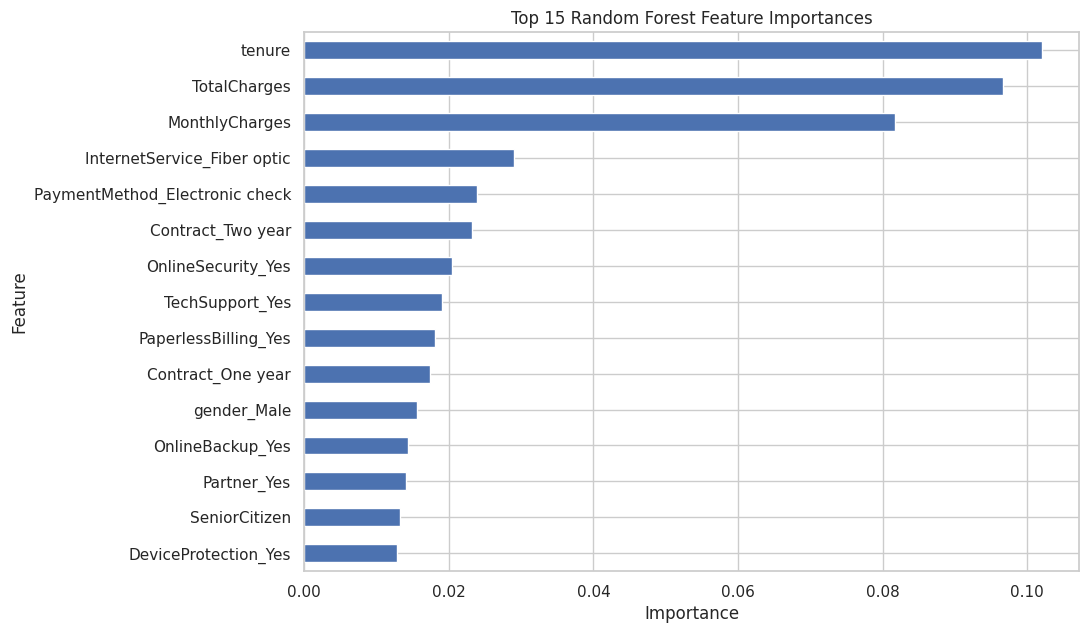

In [24]:
plt.figure(figsize=(10, 7))

importance.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [25]:
selected_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

print("Selected features for churn prediction:\n")

for feature in selected_features:
    print("-", feature)

Selected features for churn prediction:

- tenure
- MonthlyCharges
- TotalCharges
- Contract
- InternetService
- OnlineSecurity
- TechSupport
- PaymentMethod
- PaperlessBilling
- SeniorCitizen
- Partner
- Dependents


In [26]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [27]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

data = pd.read_csv(url)

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Fill missing TotalCharges
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [28]:
data["AverageMonthlySpending"] = np.where(
    data["tenure"] > 0,
    data["TotalCharges"] / data["tenure"],
    data["MonthlyCharges"]
)

print("AverageMonthlySpending created successfully!")

data[
    ["tenure", "TotalCharges", "MonthlyCharges",
     "AverageMonthlySpending"]
].head()

AverageMonthlySpending created successfully!


,tenure,TotalCharges,MonthlyCharges,AverageMonthlySpending
0,1,29.85,29.85,29.850000
1,34,1889.50,56.95,55.573529
2,2,108.15,53.85,54.075000
3,45,1840.75,42.30,40.905556
4,2,151.65,70.70,75.825000


In [29]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Convert service responses into 1/0
data["ServiceCount"] = 0

for column in service_columns:
    data["ServiceCount"] += data[column].isin(
        ["Yes", "Yes"]
    ).astype(int)

print("ServiceCount created successfully!")

data[["customerID", "ServiceCount"]].head()

ServiceCount created successfully!


,customerID,ServiceCount
0,7590-VHVEG,1
1,5575-GNVDE,3
2,3668-QPYBK,3
3,7795-CFOCW,3
4,9237-HQITU,1


In [30]:
def spending_category(value):

    if value < 50:
        return "Low"
    elif value < 100:
        return "Medium"
    else:
        return "High"


data["CustomerSpendingCategory"] = data[
    "AverageMonthlySpending"
].apply(spending_category)

print("CustomerSpendingCategory created successfully!")

data[
    ["AverageMonthlySpending", "CustomerSpendingCategory"]
].head(10)

CustomerSpendingCategory created successfully!


,AverageMonthlySpending,CustomerSpendingCategory
0,29.850000,Low
1,55.573529,Medium
2,54.075000,Medium
3,40.905556,Low
4,75.825000,Medium
5,102.562500,High
6,88.609091,Medium
7,30.190000,Low
8,108.787500,High
9,56.257258,Medium


In [31]:
engineered_features = [
    "AverageMonthlySpending",
    "ServiceCount",
    "CustomerSpendingCategory"
]

print("Engineered Features:")

for feature in engineered_features:
    print("-", feature)

print("\nSample data:")
print(
    data[
        [
            "tenure",
            "TotalCharges",
            "AverageMonthlySpending",
            "ServiceCount",
            "CustomerSpendingCategory"
        ]
    ].head()
)

Engineered Features:
- AverageMonthlySpending
- ServiceCount
- CustomerSpendingCategory

Sample data:
   tenure  TotalCharges  AverageMonthlySpending  ServiceCount  \
0       1         29.85               29.850000             1   
1      34       1889.50               55.573529             3   
2       2        108.15               54.075000             3   
3      45       1840.75               40.905556             3   
4       2        151.65               75.825000             1   

  CustomerSpendingCategory  
0                      Low  
1                   Medium  
2                   Medium  
3                      Low  
4                   Medium  


In [32]:
data_model = data.drop(columns=["customerID"])

print("customerID removed.")
print("New shape:", data_model.shape)

customerID removed.
New shape: (7043, 23)


In [33]:
data_model["Churn"] = data_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(data_model["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [34]:
X = data_model.drop(columns=["Churn"])
y = data_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [35]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'CustomerSpendingCategory']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpending', 'ServiceCount']


In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [37]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [38]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1-Score :", round(logistic_f1, 4))

LOGISTIC REGRESSION RESULTS
----------------------------------------
Accuracy : 0.7984
Precision: 0.6433
Recall   : 0.5401
F1-Score : 0.5872


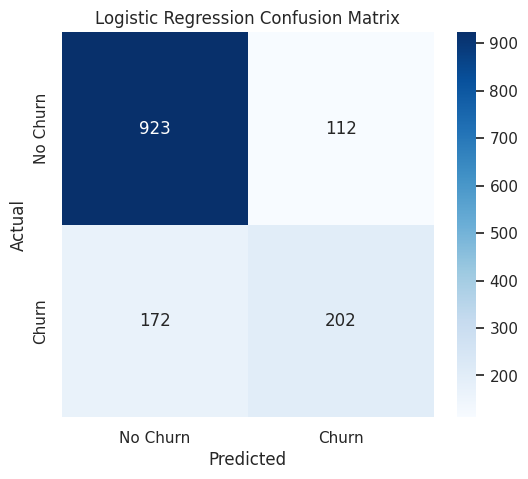

In [39]:
cm_logistic = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [40]:
print("Logistic Regression Classification Report:\n")

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.87      1035
       Churn       0.64      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [41]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [42]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_precision = precision_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("-" * 40)
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))

RANDOM FOREST RESULTS
----------------------------------------
Accuracy : 0.7892
Precision: 0.6314
Recall   : 0.4947
F1-Score : 0.5547


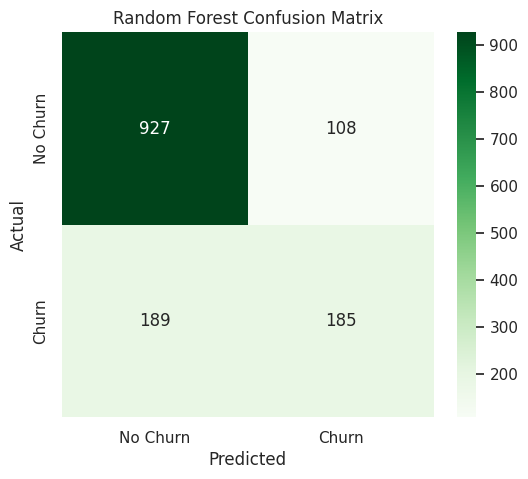

In [43]:
cm_rf = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [44]:
print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [45]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1-Score": [
        logistic_f1,
        rf_f1
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7984,0.6433,0.5401,0.5872
1,Random Forest,0.7892,0.6314,0.4947,0.5547


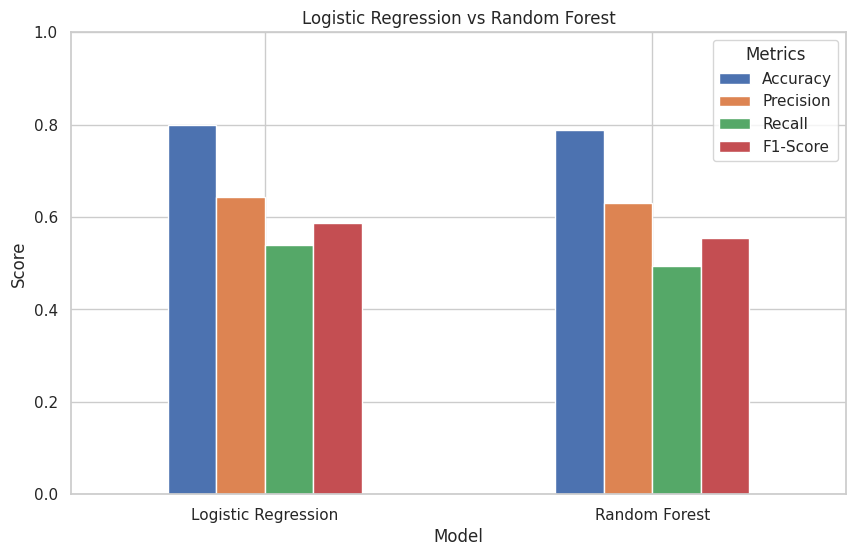

In [46]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metrics")

plt.show()

In [47]:
# Compare F1 scores
if logistic_f1 > rf_f1:
    better_model = "Logistic Regression"
    better_score = logistic_f1
elif rf_f1 > logistic_f1:
    better_model = "Random Forest"
    better_score = rf_f1
else:
    better_model = "Both models have the same F1-score"
    better_score = logistic_f1

print("Better Model based on F1-Score:")
print(better_model)

print("\nF1-Score:", round(better_score, 4))

Better Model based on F1-Score:
Logistic Regression

F1-Score: 0.5872


In [48]:
print("Engineered features added to the dataset:")
print()

for feature in engineered_features:
    print("✓", feature)

Engineered features added to the dataset:

✓ AverageMonthlySpending
✓ ServiceCount
✓ CustomerSpendingCategory


Churn percentage by spending category:
Churn                        No    Yes
CustomerSpendingCategory              
High                      70.16  29.84
Low                       84.30  15.70
Medium                    67.72  32.28


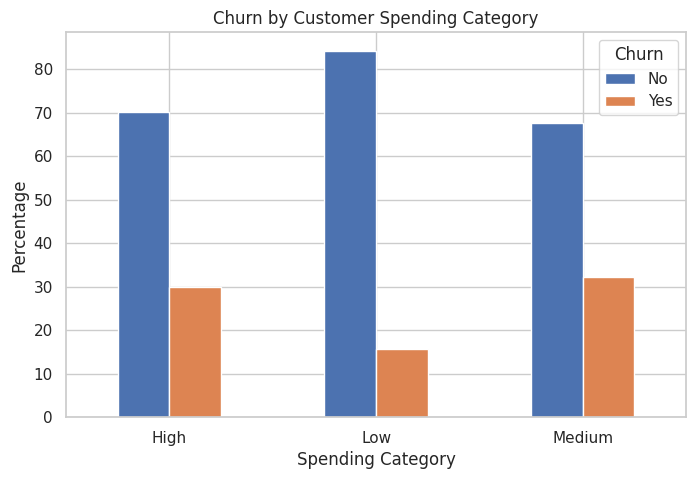

In [49]:
spending_churn = pd.crosstab(
    data["CustomerSpendingCategory"],
    data["Churn"],
    normalize="index"
) * 100

print("Churn percentage by spending category:")
print(spending_churn.round(2))

spending_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn by Customer Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

Churn percentage by ServiceCount:
Churn            No    Yes
ServiceCount              
0             56.25  43.75
1             78.89  21.11
2             67.17  32.83
3             63.52  36.48
4             68.66  31.34
5             74.45  25.55
6             77.51  22.49
7             87.59  12.41
8             94.71   5.29


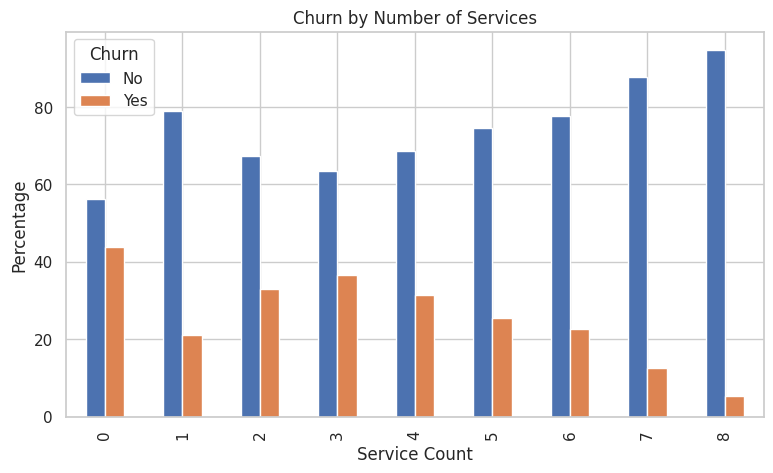

In [50]:
service_churn = pd.crosstab(
    data["ServiceCount"],
    data["Churn"],
    normalize="index"
) * 100

print("Churn percentage by ServiceCount:")
print(service_churn.round(2))

service_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn by Number of Services")
plt.xlabel("Service Count")
plt.ylabel("Percentage")
plt.legend(title="Churn")

plt.show()